# persistance/01 — temporal persistence of the goal encoding *(new corpus)*

Replicates `clock/14_goal_retention.ipynb` §2 (per-token read-out table) and §3 (affinity trajectory
across a sub-goal's implementation) on the **current** multi-predicate corpus (`src.diff.data.multi_predicate_setups`,
the `multi_pred` family used by the kv/q-transfer experiments) and the **current** goal-head JSON sets (250 / 122).

**Question:** once the model has committed to a sub-goal at its `{var} =` pivot, is that encoding *retained*
across the tokens that implement it (persistence), or *recomputed* line by line?

- §2 = qualitative read-outs to eyeball (is the verbalization stable across the sub-goal's tokens?).
- §3 = the affinity trajectory: cos(pivot encoding, encoding at 20/40/60/80/100% of the implementation),
  with the four contrast curves. Retention ⇒ curve (i) stays high & flat while (iii)/(iv) stay low.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, math, json, random, logging
sys.path.append("../..")                      # notebooks/persistance -> repo root
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # 32B ~63GB; set to free GPU(s)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import matplotlib.pyplot as plt
from rich.console import Console, Group
from rich.theme import Theme
from rich.table import Table
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.panel import Panel
from rich.markup import escape
from src.utils import logging_utils, env_utils
os.chdir(env_utils.PROJECT_ROOT); sys.path.insert(0, env_utils.PROJECT_ROOT)   # anchor CWD + imports to repo root so head_sets/ , data/ paths resolve
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)   # highlight=False: don't green token strings
def rich_print(*a, **k): console.print(*a, **k)

## 0. Model · goal heads · encoding primitive

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER, N_HEADS = mt.n_layer, mt.n_heads
SLUG = MODEL_NAME.split("/")[-1]
print(f"n_layer={N_LAYER}  n_heads={N_HEADS}  n_embd={mt.n_embd}  head_dim={mt.head_dim}")

2026-09-23 01:10:09 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-09-23 01:10:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-23 01:10:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-23 01:10:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-23 01:10:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-23 01:10:09 httpx INFO     HTTP Re

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-09-23 01:10:39 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-23 01:10:39 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-09-23 01:10:40 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_heads=40  n_embd=5120  head_dim=128


In [3]:
# ── goal heads (current JSON head sets — NOT the old head_mask.pt) ──
from scripts.evaluation.eval_goalscope import load_json_heads

HEAD_SETS = {
    250: f"head_sets/{SLUG}/goal_topk/goal__lam20_top250.json",
    122: f"head_sets/{SLUG}/goal__lam20_thr0.9_band25-56.json",
}
HEAD_BUDGET = 122                                   # <- toggle 250 / 122
goal_heads = load_json_heads(HEAD_SETS[HEAD_BUDGET], N_LAYER, N_HEADS)
print(f"{HEAD_BUDGET} goal heads · layers {min(l for l,_ in goal_heads)}-{max(l for l,_ in goal_heads)}")

122 goal heads · layers 28-55


In [4]:
# ── goal-encoding primitive (same as clock/14): the goal heads' summed residual write ──
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input

@torch.no_grad()
def goal_encoding(text, positions, heads=None, patch_interface=None):
    """(n_positions, n_embd) float32 — goal-head residual contribution at each position.
    `text` may be a str or a pre-tokenized TokenizerOutput (positions must match its tokenization)."""
    heads = goal_heads if heads is None else heads
    inp = prepare_input(prompts=text, tokenizer=mt) if isinstance(text, str) else text
    vecs = collect_head_steering_vecs(mt, inp, heads, token_positions=list(positions),
                                      patch_interface=patch_interface)
    return vecs[0]                                  # batch of 1 -> (n_pos, n_embd)

def cos(a, b):
    return float(torch.nn.functional.cosine_similarity(a.float(), b.float(), dim=-1))

## 1. Corpus (multi-predicate) — full rollout + per-condition spans

In [7]:
# ── §1 corpus: full multi-predicate rollouts (LETTER naming, seed `a=` prefilled & ignored) ──
import src.diff.data as DATA
from scripts.evaluation.eval_goalscope import _chat_prompt, greedy_continue, ALL_DATATYPES

N_SPECS   = 8
N_COND    = [3, 4]          # task sizes to mix over (>=2)
SEED      = 1123
DATATYPE  = "list[str]"     # int | str | list[int] | list[str]
GEN_MAX_NEW = 256

def build_full_prompt(inst):
    """WHOLE-function prompt in LETTER naming: signature + the FIRST predicate prefilled as
    `a = <impl>` so the model adopts a/b/c/... and writes EVERY remaining condition (the rollout
    §3 needs). The seed `a` lives in the prompt, so it never appears in `gen` and is IGNORED in the
    analysis — only b, c, ... are probed."""
    preds = inst._preds_for(inst.src_frontier)
    descs = [p.description for p in preds]
    q = DATA._question(descs, inst.datatype, inst.var_name, inst.src_lang, "listed")
    q = q.replace("computes:", "computes in sequential order:")
    base = "<code>\n" + DATA._signature(inst.datatype, inst.var_name, inst.src_lang)
    seed = DATA._assign_line(preds[0], inst.var_name, inst.src_lang, res_name="a")   # `    a = ...`
    base = base + "\n" + seed
    return _chat_prompt(mt, q, base), preds

def offsets_of(full_text):
    enc = prepare_input(prompts=full_text, tokenizer=mt, return_offsets_mapping=True)
    return [tuple(p) for p in enc.pop("offset_mapping")[0].tolist()]

def _toks_in(offsets, a_char, b_char):
    return [t for t,(a,b) in enumerate(offsets) if b>a and a<b_char and b>a_char]

PIVOT_RE = re.compile(r"(?m)^[ \t]+([A-Za-z_]\w*)\s*=(?!=)")

def _desc_for(var, preds):
    """letter var (a=0,b=1,...) -> its predicate description by position."""
    j = ord(var) - ord("a")
    return preds[j].description if 0 <= j < len(preds) else "?"

def _pid_for(var, preds):
    """letter var (a=0,b=1,...) -> its predicate id by position (for frontier targeting in §2)."""
    j = ord(var) - ord("a")
    return preds[j].id if 0 <= j < len(preds) else "?"

def _nl(s):
    return s.replace("\\n", "\n")            # defensive: render real line breaks in prints

def analyze(inst):
    """(prompt, text, offsets, conds[]) — greedy rollout after the seed `a = ...`, then per-`{var}=`
    spans. Condition `a` is prefilled and skipped; only b, c, ... are returned (contiguous idx)."""
    prompt, preds = build_full_prompt(inst)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    gen = greedy_continue(mt, **inp, max_new_tokens=GEN_MAX_NEW)
    text = prompt + gen; offs = offsets_of(text); g0 = len(prompt)
    pivots = list(PIVOT_RE.finditer(gen))
    # hard stop: the trailing `return …` / `</code>` is NOT part of any condition's impl
    _ret = re.search(r"(?m)^[ \t]*return\b", gen)
    _fence = gen.find("</code>")
    body_end = min(_ret.start() if _ret else len(gen),
                   _fence if _fence >= 0 else len(gen), len(gen))
    conds = []
    for i, m in enumerate(pivots):
        var = m.group(1)
        if var == "a":                       # the prefilled seed (should not appear in gen) — skip
            continue
        eq_char = g0 + gen.index("=", m.start())
        eq_tok  = next((t for t,(a,b) in enumerate(offs) if a<=eq_char<b), None)
        seg_start = eq_char + 1
        next_start = pivots[i+1].start() if i+1 < len(pivots) else len(gen)
        seg_end   = g0 + min(next_start, body_end)
        impl = [t for t in _toks_in(offs, seg_start, seg_end) if eq_tok is not None and t > eq_tok]
        if eq_tok is not None and impl:
            conds.append(dict(idx=len(conds), var=var, eq=eq_tok, impl=impl,
                              impl_text=text[eq_char+1:seg_end].strip(),
                              pid=_pid_for(var, preds), desc=_desc_for(var, preds)))
    return dict(inst=inst, prompt=prompt, text=text, offsets=offs, conds=conds, preds=preds)

samples = DATA.multi_predicate_setups(DATATYPE, n_conditions=N_COND, n_samples=N_SPECS,
                                      seed=SEED, naming="letters")
print(f"{len(samples)} samples · datatype={DATATYPE}")
EX = analyze(samples[0])
rich_print(Panel(Text.from_markup(
    f"[white]{escape(_nl(EX['prompt']))}[/white]"
    f"[sea_green3]{escape(_nl(EX['text'][len(EX['prompt']):]))}[/sea_green3]"),
    title="prompt (white) + rollout (green)", border_style="grey42", padding=(0,1)))
for c in EX["conds"]:
    rich_print(f"  cond {c['idx']} `{c['var']}` eq@{c['eq']} impl {c['impl'][0]}..{c['impl'][-1]}"
               f"  [grey58]{escape(c['impl_text'][:120])}[/grey58]  <- {escape(c['desc'][:60])}")


8 samples · datatype=list[str]


╭─────────────────────────────────────── prompt (white) + rollout (green) ────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes in    │
│ sequential order:                                                                                               │
│ (1) the length of the longest word                                                                              │
│ (2) the number of words shorter than three characters                                                           │
│ (3) the number of words that end with a consonant                                                               │
│ (4) whether any word is a palindrome                                                                            │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = max(len(w) for w in words) if words else 0                                                              │
│     b = sum(1 for w in words if len(w) < 3)                                                                     │
│     c = sum(1 for w in words if w[-1].lower() not in 'aeiou' and w[-1].isalpha())                               │
│     d = any(w == w[::-1] for w in words)                                                                        │
│     return a, b, c, d                                                                                           │
│ </code>                                                                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

cond 0 `b` eq@147 impl 148..162  sum(1 for w in words if len(w) < 3)  <- the number of words shorter than three 
characters

cond 1 `c` eq@165 impl 166..193  sum(1 for w in words if w[-1].lower() not in 'aeiou' and w[-1].isalpha())  <- 
the number of words that end with a consonant

cond 2 `d` eq@196 impl 197..208  any(w == w[::-1] for w in words)  <- whether any word is a palindrome

## 2. Faithfulness read-out through the implementation  *(qualitative — for eyeballing)*

For a couple of example conditions, verbalize the goal-head encoding (GoalScope, **faithfulness / natural-language** read-out — no causality) at the `=` pivot and along each implementation token. Set `TARGET_PRED` to a predicate id (e.g. `has_palindrome` for `list[str]`, `is_palindrome` for `int`/`str`) to pick which frontier to inspect; ids come from `[p.id for p in DATA.QTASKS[DATATYPE].predicates]`.

In [19]:
from src.goals.goalscope import apply_goalscope
from src.goals import temporal_persistence as TP     # canonical frontier-prefill pipeline

# Faithfulness read-out ONLY (natural-language verbalization of the goal-head encoding); no causality.
GS = dict(selected_heads=goal_heads, strategy="additive_norm", alpha=0.1,
          steer_layer_range=(35, 46), n_steer_tokens="all", max_new_tokens=48)

# ── build a targeted condition DIRECTLY, FRONTIER-PREFILLED up to `{var} =` ──────────────
# The listed spec is exactly SPEC_IDS (order preserved). Conditions BEFORE the target are prefilled as
# full lines; the TARGET is prefilled only up to its `=` (python `    b =` / c++ `    auto b =`), so the
# `=` pivot sits at the prompt boundary and the model writes only the target's VALUE — identical to the
# temporal-persistence probe (TP.build_probe_prompt). SPEC_IDS[0] is the seed `a`; the target may sit in
# any middle slot.  ids: [p.id for p in DATA.QTASKS[DATATYPE].predicates]
# TARGET_PRED = "has_palindrome"                                         
# SPEC_IDS    = ["total_length", "has_palindrome", "count_capitalized"] 
# TARGET_PRED = "count_starts_vowel"                                         
# SPEC_IDS    = ["total_length", "count_starts_vowel", "has_palindrome"]

DATATYPE  = "list[int]"     # int | str | list[int] | list[str]
TARGET_PRED = "value_range"                                          # <- toggle
SPEC_IDS    = ["has_duplicate", "value_range", "is_sorted"]

LANGS       = ["python"]                                                 # one table per language, e.g. ["python","cpp"]
MAX_NEW     = 96                                                          # generation budget for the value
USE_ORACLE  = None                                                       # None=auto (oracle for C++), or True/False

BANK = {p.id: p for p in DATA.QTASKS[DATATYPE].predicates}
assert all(i in BANK for i in SPEC_IDS), f"unknown id in SPEC_IDS; bank: {sorted(BANK)}"
assert len(SPEC_IDS) >= 2, "need a seed + at least one probed condition"
assert TARGET_PRED in SPEC_IDS[1:], "TARGET_PRED must be a probed (non-seed) entry of SPEC_IDS"
if TARGET_PRED == SPEC_IDS[-1]:
    rich_print("[yellow]note: TARGET_PRED is the LAST entry of SPEC_IDS — move it earlier for a mid-spec target.[/yellow]")

def build_condition(spec_ids, lang, other_id=None):
    """Plain MultiPredicateInstance whose listed spec is exactly `spec_ids` (order preserved). Only used
    to carry (datatype, shared, src_frontier, var_name, lang) into TP.build_probe_prompt below."""
    shared = tuple(BANK[i] for i in spec_ids[:-1])
    if other_id is None:
        other_id = next(pid for pid in BANK if pid not in spec_ids)
    return DATA.MultiPredicateInstance(
        datatype=DATATYPE, shared=shared, src_frontier=BANK[spec_ids[-1]], dst_frontier=BANK[other_id],
        var_name=DATA.QTASKS[DATATYPE].var_names[0], presentation="listed",
        src_lang=lang, dst_lang=lang, naming="letters", letter_stub="indent",
        meta={"datatype": DATATYPE, "dst_next": other_id, "n_conditions": len(shared) + 1})

def probe_target(spec_ids, target_pred, lang):
    """Frontier-prefill the prompt up to the target's `{var} =`, roll out its value, and locate the
    (pivot, value-token) positions. Returns (prompt, full_text, positions, tv, desc, value_str)."""
    inst  = build_condition(spec_ids, lang)
    preds = inst._preds_for(inst.src_frontier)                 # == spec_ids order
    t     = spec_ids.index(target_pred)                        # target position (1 ≤ t < len)
    prompt, tv = TP.build_probe_prompt(mt, inst, preds, t)     # prefills up to `{tv} =`
    full_text  = TP.rollout_probe(mt, prompt, max_new=MAX_NEW) # model writes only the value
    gen        = full_text[len(prompt):]
    next_var   = TP._letter(t + 1) if t + 1 < len(preds) else None
    use_oracle = (lang == "cpp") if USE_ORACLE is None else USE_ORACLE
    if use_oracle:
        code_prefix = prompt.split("<code>\n", 1)[-1] if "<code>\n" in prompt else prompt
        seg = TP.oracle_value_segment(code_prefix, tv, preds[t].description, gen)
    else:
        seg = TP.rule_based_value(gen, tv, next_var)
    if not seg:
        return None
    offs = TP._offsets(mt, full_text)
    P    = TP.prompt_boundary(mt, prompt, full_text)
    loc  = TP.locate_value(offs, full_text, len(prompt), P, seg)
    if loc is None:
        return None
    eq_tok, impl = loc
    return prompt, full_text, [eq_tok] + impl, tv, preds[t].description, seg

def readout_table(full_text, positions, pid, var, value_str):
    """Faithfulness (NL) read-out + cos-with-pivot of the aggregated goal vector, at the `=` pivot and
    along the value tokens. `cos(=)` = cosine of the goal-head write at a position with the write at the
    pivot (=) — the quantity the temporal-persistence curves aggregate."""
    tok_inp = prepare_input(prompts=full_text, tokenizer=mt)
    ids = tok_inp.input_ids[0].tolist()
    faith = {r["pos"]: r for r in apply_goalscope(tok_inp, mt=mt, show=False, include_noncode=False,
                                                  token_positions=positions, **GS)}
    enc = goal_encoding(tok_inp, positions)          # (n_pos, n_embd) aggregated goal-head write
    piv = enc[0]                                      # vector at the pivot (=)
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False,
              title=escape(f"[{pid}]  {var} = {value_str[:80]}"))
    t.add_column("token", no_wrap=True, style="bold", justify="right")
    t.add_column("progress", no_wrap=True, justify="right", style="grey58")
    t.add_column("cos(=)", no_wrap=True, justify="right", style="cyan")
    t.add_column("F (faithfulness / NL verbalization)", overflow="fold", style="sea_green3", ratio=1)
    n = len(positions) - 1                            # value tokens (positions[0] is the pivot)
    for k, p in enumerate(positions):
        tok  = mt.tokenizer.decode([ids[p]])
        f    = (faith.get(p, {}).get("patched_gen") or "").strip().replace("\n", " ↵ ")
        # progress matches the figure's grid (_prog_vec): the pivot (=) is 0%, value token k is k/n,
        # so the last value token is 100% — the table row labelled x% is the token the figure plots at x%.
        prog = "0% (=)" if k == 0 else f"{round(100 * k / n)}%"
        t.add_row(repr(tok), prog, f"{cos(enc[k], piv):+.3f}", escape(f))
    return t

def show_prompt(prompt, desc, pid, var):
    """Print the full frontier-prefilled prompt (ends at `{var} =`) with the target sub-goal highlighted
    in the listed spec."""
    esc = escape(_nl(prompt)); tgt = escape(desc)
    if tgt and tgt in esc:
        esc = esc.replace(tgt, f"[black on yellow]{tgt}[/black on yellow]", 1)
    rich_print(Panel(Text.from_markup(esc),
                     title=escape(f"prompt · target = [{pid}] {var} ({desc})  (prefilled up to `{var} =`)"),
                     border_style="grey42", padding=(0, 1)))

# ── build · roll out · render (deterministic — one forward pass per language) ────────────
for lang in LANGS:
    res = probe_target(SPEC_IDS, TARGET_PRED, lang)
    if res is None:
        rich_print(f"[red]could not build/segment {TARGET_PRED} for lang={lang}[/red]"); continue
    prompt, full_text, positions, tv, desc, value_str = res
    rich_print(f"[grey58]lang={lang}  ·  spec={SPEC_IDS}  ·  target `{tv}` "
               f"({len(positions)-1} value tokens)[/grey58]")
    show_prompt(prompt, desc, TARGET_PRED, tv)
    rich_print(readout_table(full_text, positions, TARGET_PRED, tv, value_str))

lang=python  ·  spec=['has_duplicate', 'value_range', 'is_sorted']  ·  target `b` (7 value tokens)

╭─ prompt · target = [value_range] b (the difference between the maximum and minimum values)  (prefilled up to `b─╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of integers `nums`, computes in    │
│ sequential order:                                                                                               │
│ (1) whether any value appears more than once                                                                    │
│ (2) the difference between the maximum and minimum values                                                       │
│ (3) whether the values are sorted in non-decreasing order                                                       │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(nums: list[int]):                                                                                      │
│     a = len(set(nums)) != len(nums)                                                                             │
│     b =                                                                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

                                     [value_range]  b = max(nums) - min(nums)                                      
                                                                                                                   
   token   progress   cos(=)   F (faithfulness / NL verbalization)                                                 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
    ' ='     0% (=)   +1.000   To determine what is happening at a specific line of code, you need to find the     
                               difference between the maximum and minimum values in the list or array. This can be 
                               done by subtracting the minimum value from the maximum value. Here's how            
  ' max'        14%   +0.837   I need to see the specific line or the range of values in your code to determine    
                               what it's doing. Please provide the maximum and minimum values, or the line with    
                               the highest and lowest numbers, to find out.                                        
 '(nums'        29%   +0.809   I need to see the code to determine the difference between the maximum and minimum  
                               values, which will give me the range. Subtract the minimum value from the maximum   
                               value to find this difference.                                                      
     ')'        43%   +0.839   I need to see the specific line of code to determine the difference between the     
                               maximum and minimum values, or the difference between the first and last elements   
                               if the list is not sorted. Subtract the minimum value from the maximum value, or    
                               subtract the                                                                        
    ' -'        57%   +0.820   I need to see the specific line of code to determine what it's doing. Please        
                               provide the minimum and maximum values from the list or array to find the           
                               difference.                                                                         
  ' min'        71%   +0.709   I need to see the specific line or the range of values in your code to determine    
                               what it's doing. Please provide the minimum and maximum values, or the entire list  
                               if it's not sorted.                                                                 
 '(nums'        86%   +0.778   I need to see the specific line of code to determine what it's doing. Please        
                               provide the line or the array if you have it.                                       
   ')\n'       100%   +0.554   I'm checking if the current line is the last element in the list after sorting it,  
                               indicating whether the list is sorted or not.                                      

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

saved -> /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/readout_value_range_python.tex

% \textbf{value\_range} (\texttt{b}, python); frontier-prefilled to \texttt{b =}; value = \texttt{max(nums) - min(nums)}
\begin{tabular}{l r r p{7cm}}
\toprule
token & progress & $\cos(=)$ & faithfulness read-out (NL) \\
\midrule
\texttt{ =} & 0\% ($=$) & $+1.000$ & To determine what is happening at a specific line of code, you need to find the difference between the maximum and minimum values in the list or array. This can be done by subtracting the minimum value from the maximum value. Here's how \\
\texttt{ max} & 14\% & $+0.837$ & I need to see the specific line or the range of values in your code to determine what it's doing. Please provide the maximum and minimum values, or the line with the highest and lowest numbers, to find out. \\
\texttt{(nums} & 29\% & $+0.809$ & I need to see the code to determine the difference between the maximum and minimum values, which will give me the range. Subtract the minimum value from the maximum value to find this difference. \\
\texttt{)} & 43

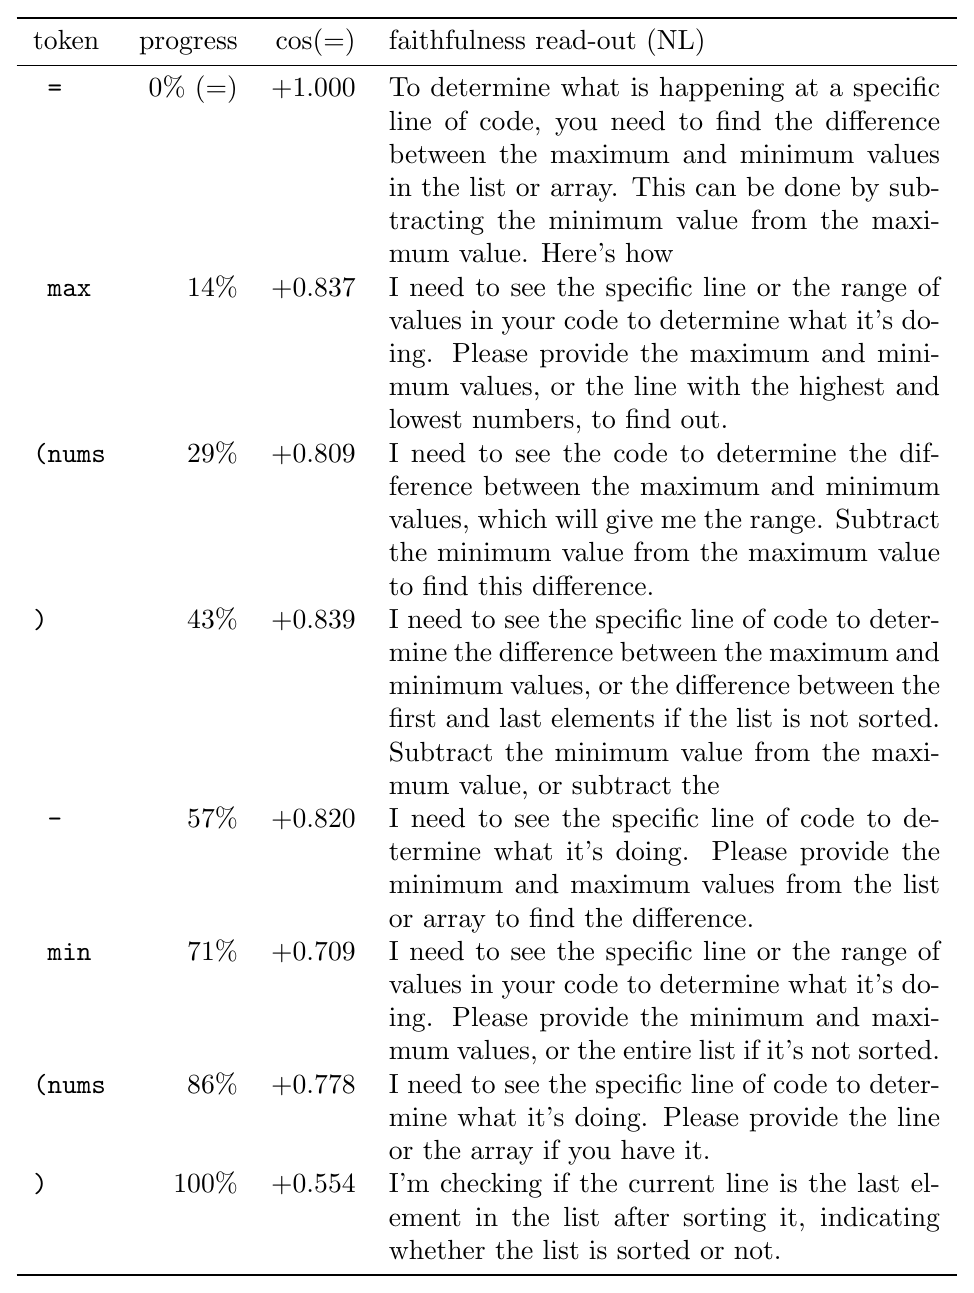

: 

In [ ]:
# ── LaTeX table of the SELECTED config's read-out (saved + rendered inline for feedback) ──
import os, re, sys
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT, "notebooks", "fig_n_table_generators"))
import figstyle as F
from IPython.display import display

_TEXMAP = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
           "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
           "^": r"\textasciicircum{}", "<": r"\textless{}", ">": r"\textgreater{}", "|": r"\textbar{}"}
def _texesc(s):
    return re.sub("|".join(re.escape(k) for k in _TEXMAP), lambda m: _TEXMAP[m.group()], s)

def latex_readout_table(full_text, positions, pid, var, value_str, lang):
    """Booktabs table for ONE probed condition: per-token progress / cos(=) / faithfulness read-out.
    Progress uses the figure convention (pivot `=` is 0%, last value token is 100%)."""
    tok_inp = prepare_input(prompts=full_text, tokenizer=mt)
    ids = tok_inp.input_ids[0].tolist()
    faith = {r["pos"]: r for r in apply_goalscope(tok_inp, mt=mt, show=False, include_noncode=False,
                                                  token_positions=positions, **GS)}
    enc = goal_encoding(tok_inp, positions); piv = enc[0]
    n = len(positions) - 1
    lines = []
    for k, pos in enumerate(positions):
        tok  = _texesc(mt.tokenizer.decode([ids[pos]]))
        f    = _texesc((faith.get(pos, {}).get("patched_gen") or "").strip().replace("\n", " "))
        prog = r"0\% ($=$)" if k == 0 else f"{round(100 * k / n)}\\%"
        lines.append(f"\\texttt{{{tok}}} & {prog} & ${cos(enc[k], piv):+.3f}$ & {f}")
    body = " \\\\\n".join(lines)
    header = (f"\\textbf{{{_texesc(pid)}}} (\\texttt{{{var}}}, {lang}); frontier-prefilled to "
              f"\\texttt{{{var} =}}; value = \\texttt{{{_texesc(value_str[:60])}}}")
    tex = ("% " + header + "\n"
           "\\begin{tabular}{l r r p{7cm}}\n\\toprule\n"
           "token & progress & $\\cos(=)$ & faithfulness read-out (NL) \\\\\n\\midrule\n"
           f"{body} \\\\\n\\bottomrule\n\\end{{tabular}}")
    return tex

outdir = os.path.join(env_utils.PROJECT_ROOT, "notebooks", "Figures", "temporal_persistence")
os.makedirs(outdir, exist_ok=True)
for lang in LANGS:
    res = probe_target(SPEC_IDS, TARGET_PRED, lang)
    if res is None:
        rich_print(f"[red]probe failed for lang={lang}[/red]"); continue
    prompt, full_text, positions, tv, desc, value_str = res
    tex = latex_readout_table(full_text, positions, TARGET_PRED, tv, value_str, lang)
    path = os.path.join(outdir, f"readout_{TARGET_PRED}_{lang}.tex")
    with open(path, "w") as fh:
        fh.write(tex + "\n")
    rich_print(f"[grey58]saved -> {path}[/grey58]")
    print(tex)                                   # LaTeX source (copy into the paper)
    img = F.render_latex_table(tex)              # inline compiled preview for feedback
    if img is not None:
        display(img)
    else:
        rich_print("[yellow](inline LaTeX render failed — .tex saved & printed above)[/yellow]")

## 3. Affinity trajectory across the rollout  *(retention vs recomputation)*

**TARGET_SIGNAL** = the goal encoding at a condition's `=` pivot (0% progression). For every condition we
read the encoding at 20/40/60/80/100% of its implementation and compute cosine to its own TARGET_SIGNAL,
plus three contrast curves:

- **(i) same condition** — same pivot vs its own rollout (retention curve).
- **(ii) same pred, diff ctx** — same predicate in a different function.
- **(iii) diff pred, same ctx** / **(iv) diff pred, diff ctx** — the floors.

**Retention** ⇒ (i) flat & high, (ii) below it but above the floors, (iii)/(iv) low. **Recomputation** ⇒
(i) decays toward the floor as the implementation is written. `N_TRIALS` is small by default (vibe-check).

In [ ]:
# ── §3a: forward passes → per-condition (pivot + rollout) encodings → the four cosine curves ──
# (numbers only; visualization is the next cell so you can re-plot without re-running forwards)
# CONDS (the expensive forward passes) are cached under results/notebook_caches — re-runs are free
# unless a knob below changes (or FORCE_RECOMPUTE=True).
import os, hashlib
from tqdm.auto import tqdm
from src.utils import env_utils

N_TRIALS  = 64                       # contexts (knob — keep small for a quick pass)
PROG_GRID = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
MIN_IMPL  = 4                        # drop conditions with too-short implementations
FORCE_RECOMPUTE = False              # set True to ignore the cache and re-run the forwards

# cache key: every knob that changes the forwards (PROG_GRID is NOT here — it is consumed in §3b)
_key = dict(model=MODEL_NAME, head_budget=HEAD_BUDGET, head_set=HEAD_SETS[HEAD_BUDGET],
            datatype=DATATYPE, n_cond=N_COND, n_trials=N_TRIALS, seed=SEED,
            min_impl=MIN_IMPL, gen_max_new=GEN_MAX_NEW, primitive="goal_heads_resid_write_v1")
_h = hashlib.md5(repr(sorted(_key.items())).encode()).hexdigest()[:16]
_cache_dir = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_caches",
                          "temporal_persistence", SLUG)
os.makedirs(_cache_dir, exist_ok=True)
_cache_path = os.path.join(_cache_dir, f"conds_{_h}.pt")

if os.path.exists(_cache_path) and not FORCE_RECOMPUTE:
    CONDS = torch.load(_cache_path)["conds"]
    print(f"loaded {len(CONDS)} conditions from cache -> {_cache_path}")
else:
    CONDS = []
    for t, s in enumerate(tqdm(DATA.multi_predicate_setups(DATATYPE, n_conditions=N_COND,
                                n_samples=N_TRIALS, seed=SEED, naming="letters"), desc="contexts")):
        anz = analyze(s)
        for c in anz["conds"]:
            if len(c["impl"]) < MIN_IMPL:
                continue
            E = goal_encoding(anz["text"], [c["eq"]] + c["impl"])
            CONDS.append(dict(ctx=t, pred=c["desc"], pivot=E[0].clone().cpu(),
                              traj=E[1:].clone().cpu(), n_impl=len(c["impl"])))
    torch.save({"conds": CONDS, "key": _key}, _cache_path)
    print(f"{len(CONDS)} conditions from {N_TRIALS} contexts -> cached to {_cache_path}")

contexts:   0%|          | 0/64 [00:00<?, ?it/s]

curves ready — run the next cell to visualize (no forwards needed to re-plot)


           cos(TARGET_SIGNAL, encoding at x% of rollout) — 157 conditions (122 heads, list; mean ± sem)            
┏━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ comparison   ┃ n pairs ┃           0% ┃          20% ┃          40% ┃          60% ┃          80% ┃        100% ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ i   same     │     157 │ +1.000±0.000 │ +0.754±0.007 │ +0.714±0.008 │ +0.725±0.010 │ +0.750±0.006 │ +0.458±0.0… │
│ condition    │         │              │              │              │              │              │             │
│ ii  same     │    1454 │ +0.917±0.001 │ +0.710±0.002 │ +0.676±0.003 │ +0.675±0.003 │ +0.710±0.002 │ +0.425±0.0… │
│ pred, diff   │         │              │              │              │              │              │             │
│ ctx          │         │              │              │              │              │              │             │
│ iii diff     │     244 │ +0.524±0.008 │ +0.395±0.007 │ +0.371±0.007 │ +0.367±0.007 │ +0.354±0.007 │ +0.473±0.0… │
│ pred, same   │         │              │              │              │              │              │             │
│ ctx          │         │              │              │              │              │              │             │
│ iv  diff     │   22794 │ +0.484±0.001 │ +0.360±0.001 │ +0.338±0.001 │ +0.344±0.001 │ +0.338±0.001 │ +0.348±0.0… │
│ pred, diff   │         │              │              │              │              │              │             │
│ ctx          │         │              │              │              │              │              │             │
└──────────────┴─────────┴──────────────┴──────────────┴──────────────┴──────────────┴──────────────┴─────────────┘

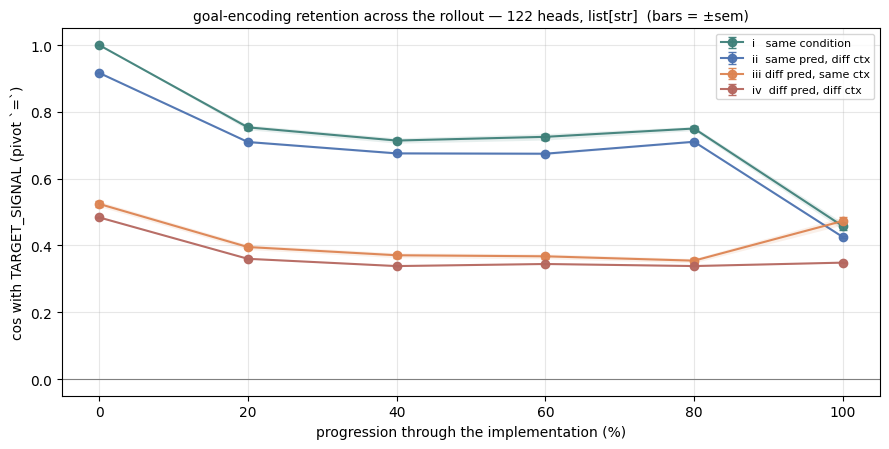

: 

In [ ]:
def prog_vec(c, p):
    if p <= 0: return c["pivot"]
    n = c["n_impl"]; return c["traj"][min(n-1, max(0, math.ceil(p*n)-1))]

def _unit(M):
    M = M.float(); return (M / M.norm(dim=-1, keepdim=True)).numpy()

P  = _unit(torch.stack([c["pivot"] for c in CONDS]))
G  = {p: _unit(torch.stack([prog_vec(c, p) for c in CONDS])) for p in PROG_GRID}
pred = np.array([c["pred"] for c in CONDS]); ctx = np.array([c["ctx"] for c in CONDS])
same_pred = pred[:, None] == pred[None, :]; same_ctx = ctx[:, None] == ctx[None, :]
eye = np.eye(len(CONDS), dtype=bool)
MASKS = {"i   same condition": eye,
         "ii  same pred, diff ctx": same_pred & ~same_ctx,
         "iii diff pred, same ctx": ~same_pred & same_ctx,
         "iv  diff pred, diff ctx": ~same_pred & ~same_ctx}
COLOR = {"i   same condition":"#3f8079","ii  same pred, diff ctx":"#4c72b0",
         "iii diff pred, same ctx":"#dd8452","iv  diff pred, diff ctx":"#b5675f"}

# curves[name][p] = (mean, std, sem, n) over all matched off-diagonal (or diagonal) pairs
curves = {}
for name, m in MASKS.items():
    curves[name] = {}
    for p in PROG_GRID:
        v = (P @ G[p].T)[m]
        if len(v):
            mu = float(v.mean()); sd = float(v.std(ddof=1)) if len(v) > 1 else 0.0
            curves[name][p] = (mu, sd, sd/np.sqrt(len(v)), len(v))
        else:
            curves[name][p] = (np.nan, np.nan, np.nan, 0)
print("curves ready — run the next cell to visualize (no forwards needed to re-plot)")

# ── §3b: visualize — table + curves with error bars (decoupled from the forwards above) ──
ERR = "sem"                          # "std" -> ± standard deviation | "sem" -> ± standard error
_ei = 1 if ERR == "std" else 2       # index into (mean, std, sem, n)

tbl = Table(title=f"cos(TARGET_SIGNAL, encoding at x% of rollout) — {len(CONDS)} conditions "
                  f"({HEAD_BUDGET} heads, {DATATYPE}; mean ± {ERR})")
tbl.add_column("comparison"); tbl.add_column("n pairs", justify="right")
for p in PROG_GRID: tbl.add_column(f"{int(p*100)}%", justify="right")
for name in MASKS:
    tbl.add_row(name, str(curves[name][PROG_GRID[0]][3]),
                *[f"{curves[name][p][0]:+.3f}±{curves[name][p][_ei]:.3f}" for p in PROG_GRID])
rich_print(tbl)

fig, ax = plt.subplots(figsize=(9, 4.6)); xs = [p*100 for p in PROG_GRID]
for name in MASKS:
    mu = np.array([curves[name][p][0]  for p in PROG_GRID])
    er = np.array([curves[name][p][_ei] for p in PROG_GRID])
    ax.errorbar(xs, mu, yerr=er, fmt="o-", color=COLOR[name], label=name,
                capsize=3, elinewidth=1, alpha=0.95)
    ax.fill_between(xs, mu-er, mu+er, color=COLOR[name], alpha=0.12, lw=0)
ax.set_xlabel("progression through the implementation (%)")
ax.set_ylabel("cos with TARGET_SIGNAL (pivot `=`)")
ax.set_title(f"goal-encoding retention across the rollout — {HEAD_BUDGET} heads, {DATATYPE}  "
             f"(bars = ±{ERR})", fontsize=10)
ax.axhline(0, color="grey", lw=.8); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


### Notes / caveats
- **Span finder is regex-based** (`^\\s+{var} =` → next such pivot), not the oracle labelling `clock/14` §3
  used. For multi-step predicates with an inner temp-var assignment (`for d in …: d = int(d)`) the span may
  truncate early — good enough for a vibe-check; switch to `src.goals.multistep_label.label_generation` if you
  systematise this.
- **GS read-out config** is the 122-band setting; re-tune (`additive_norm`, α) for 250 heads before trusting §2.
- To draw a **fresh** set of contexts (cache is in-memory here), bump `SEED`. Increase `N_TRIALS` for a real run.

In [ ]:
type(((1)))

int